# 01 - Data audit

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../challenge_data")

cpu = pd.read_csv(DATA_DIR / "vm_cpu_readings.csv.gz")
meta = pd.read_csv(DATA_DIR / "vm_metadata.csv.gz")

### Expected shape

| | Rows | Columns |
|---|---|---|
| cpu  | 10 000 × 134 = 1 340 000 | 5 |
| meta | 10 000 | 11 |

In [2]:
print(cpu.shape, meta.shape)
cpu.head()

(1340000, 5) (10000, 11)


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


In [3]:
cpu.dtypes

timestamp      int64
vm_id            str
min_cpu      float64
max_cpu      float64
avg_cpu      float64
dtype: object

In [4]:
ts = sorted(cpu["timestamp"].unique())
print("unique timestamps:", len(ts))
print("range:", ts[0], "to", ts[-1], "seconds")
print("steps between neighbours:", pd.Series(ts).diff().value_counts())

unique timestamps: 134
range: 0 to 39900 seconds
steps between neighbours: 300.0    133
Name: count, dtype: int64


In [5]:
per_vm = cpu.groupby("vm_id")["timestamp"].agg(["count", "min", "max"])
print(per_vm["count"].value_counts())
print("distinct starts:", per_vm["min"].nunique(), "| distinct ends:", per_vm["max"].nunique())

count
134    10000
Name: count, dtype: int64
distinct starts: 1 | distinct ends: 1


In [6]:
print("duplicate (vm_id, timestamp):", cpu.duplicated(["vm_id", "timestamp"]).sum())
print(cpu.isna().sum())

duplicate (vm_id, timestamp): 0
timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64


### Findings: time grid and completeness

- **134 timestamps**, 0 → 39 900 s (~11.1 h), **regular 300 s step**, no gaps.
- **Every VM has all 134 readings**: one common start and end for all 10 000 VMs.
- **No duplicates** on `(vm_id, timestamp)` and **no missing values**.

**Why it matters:**
- `active_vm_count` is **constant at 10 000** by construction: the release keeps only
  complete VM traces (see `challenge_data/DATA_CARD.md`). A persistence forecast is exact,
  so no model is needed for this target. I still produce it as required.
- VM **churn is not observable** in the CPU readings because of this selection.
  I look at creation/deletion timestamps in the metadata instead (below).
- The real forecasting problem is `aggregate_cpu_utilization`.

## CPU utilization distributions

In [7]:
cpu[["min_cpu", "avg_cpu", "max_cpu"]].describe().round(2)

,min_cpu,avg_cpu,max_cpu
count,1340000.00,1340000.00,1340000.00
mean,6.16,9.39,18.35
std,11.76,14.27,21.62
min,0.00,0.01,0.02
25%,1.49,2.48,4.42
50%,3.23,5.11,9.12
75%,5.33,9.62,23.62
max,99.28,99.49,99.70


In [8]:
cols = ["min_cpu", "avg_cpu", "max_cpu"]
print("outside [0, 100]:", ((cpu[cols] < 0) | (cpu[cols] > 100)).sum().to_dict())
print("min > avg:", (cpu["min_cpu"] > cpu["avg_cpu"]).sum())
print("avg > max:", (cpu["avg_cpu"] > cpu["max_cpu"]).sum())

outside [0, 100]: {'min_cpu': 0, 'avg_cpu': 0, 'max_cpu': 0}
min > avg: 0
avg > max: 0


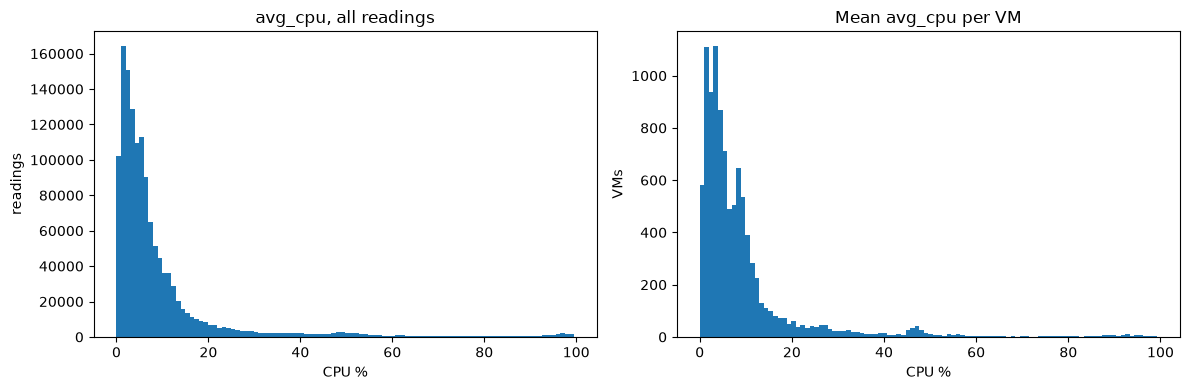

In [9]:
vm_mean = cpu.groupby("vm_id")["avg_cpu"].mean()
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].hist(cpu["avg_cpu"], bins=100)
axes[0].set(title="avg_cpu, all readings", xlabel="CPU %", ylabel="readings")
axes[1].hist(vm_mean, bins=100)
axes[1].set(title="Mean avg_cpu per VM", xlabel="CPU %", ylabel="VMs")
plt.tight_layout()
plt.show()


In [10]:
for t in [20, 50, 80]:
    print(f"VMs with mean avg_cpu > {t}% {(vm_mean > t).mean():.1%}")

VMs with mean avg_cpu > 20% 9.8%
VMs with mean avg_cpu > 50% 2.2%
VMs with mean avg_cpu > 80% 0.9%


### Findings: CPU distributions

- All readings are within [0, 100] and satisfy `min ≤ avg ≤ max`.
- Strongly **right-skewed**: mean `avg_cpu` is 9.4% vs median 5.1%;
  75% of readings are below 9.6%. Most VMs are lightly loaded.
- A small tail of VMs runs hot: 2.2% of VMs average above 50%, 0.9% above 80%.
- Within-interval peaks are ~2× the average (median `max_cpu` 9.1% vs `avg_cpu` 5.1%).

**Why it matters:**
- `aggregate_cpu_utilization` is a **mean**, so it is sensitive to the few heavy VMs:
  a change in a small group can move the aggregate noticeably.
- 5-minute averages hide short bursts: a capacity policy based on `avg_cpu` alone
  will underestimate peak demand; `max_cpu` is relevant for headroom.